# Filtrul Bayes

Filtrul Bayes este o metoda recusiva de estimare a unei distributii de probabilitate. In robotica, filtrele Bayes sunt des folosite pentru a estima pozitia si orientarea. 

Notam starea sistemului la momentul k cu $\mathbf{x}_k$, continand variabilele de interes ale robotului (ex. pozitie in plan (x,y) si orientarea ).
$$\mathbf{x}_k = \begin{bmatrix} x_k \\ y_k \\ \theta_k \end{bmatrix}$$

Notam cu $p(\mathbf{x}_k \mid \mathbf{z}_{1:k})$ distributia probabilitatii ca robotul sa se afle in starea $\mathbf{x}_k$, conditionata de masuratorile colectate pana la momentul respectiv. Daca nu avem nici o informatie initiala, putem considera distibutia uniforma. In continuare vom folosi un exemplu discret, cu deplasare intr-o singura dimensiune, cu vectorul de stare format doar din indexul celulei. <br>
<p align="center">
  <img src="media/dist_unif.png" alt="Distributie uniforma" width="800">
</p>

Notam cu $p(\mathbf{x}_k \mid \mathbf{z}_{1:k})$ distributia de probabilitate pentru masuratori, conditionate de starea $\mathbf{x}_k$.
Exemplele de mai jos folosesc un senzor binar. Sansa lui de a oferi culoarea corecta este de 75%, iar in 25% din cazuri ofera culoarea gresita. Actualizarea distributiei se realizeaza per celula prin inmultirea probabilitatii ca robotul sa fie in celula respectiva cu probabilitatea ca senzorul sa ofere culoarea celulei.

In [57]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from IPython.display import display, clear_output

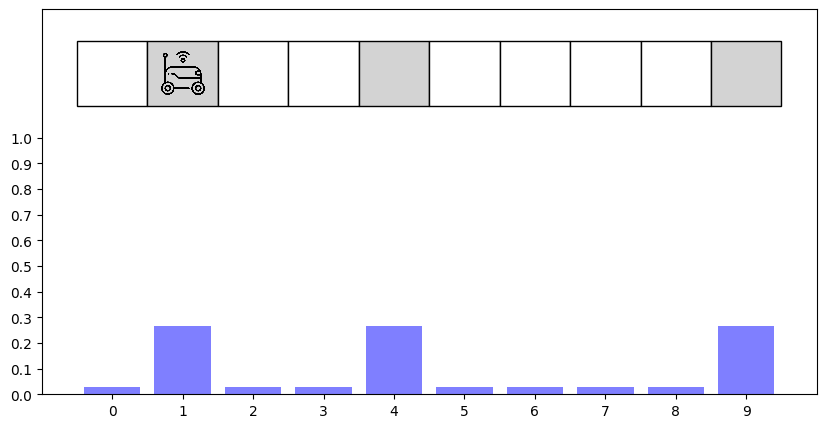

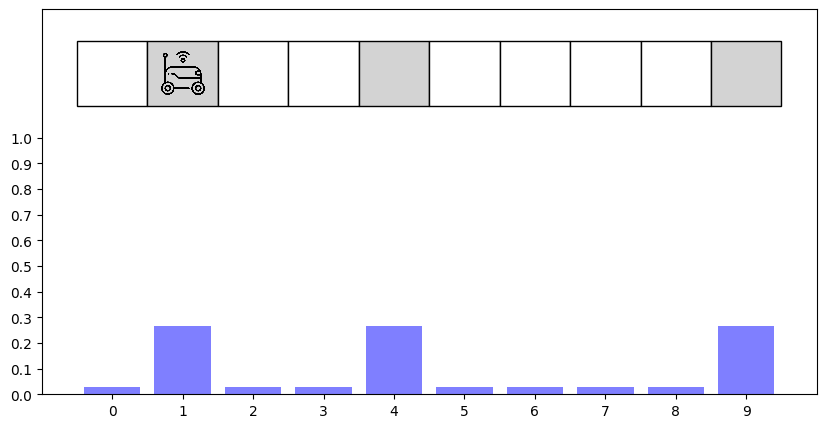

In [58]:
# Visual Parameters
cell_width = 1
cell_height = 0.25

# Demo Parameters
map_ = [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
prob = np.full(len(map_), 1.0/len(map_), dtype=np.float32)
prob_hit = 0.75
prob_miss = 1.0 - prob_hit
measurements = [1, 1, 1, 0]
robot_index = 1

fig, ax = plt.subplots(figsize=(10, 5))

# Draw the map
for i in range(len(map_)):
    if map_[i]:
        color = 'lightgray'
    else:
        color = 'white'
    square = mpatches.Rectangle((i * cell_width - cell_width/2, 1.25-cell_height/2), cell_width, cell_height, facecolor=color, edgecolor='black', linewidth=1)
    ax.add_patch(square)

# Draw the probability bars
bars = ax.bar(range(len(prob)), prob, color='blue', alpha=0.5, label='Probability')
ax.set_ylim(0,1.5)
ax.set_xticks(range(len(map_)))
ax.set_yticks(np.arange(0, 1.1, 0.1))

# Draw the robot icon
robot_icon = mpimg.imread('media/robot.png')
imagebox = OffsetImage(robot_icon, zoom=0.075)
ax.add_artist(AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False))

display(fig)

# Update the probabilities based on measurements
for m in measurements:
    for i in range(len(prob)):
        if map_[i] == m:
            prob[i] *= prob_hit
        else:
            prob[i] *= prob_miss

    prob /= np.sum(prob)
    

    input("Press Enter for a new measure...")

    for bar, z in zip(bars, prob):
        bar.set_height(z)
    clear_output(wait=True)
    display(fig)


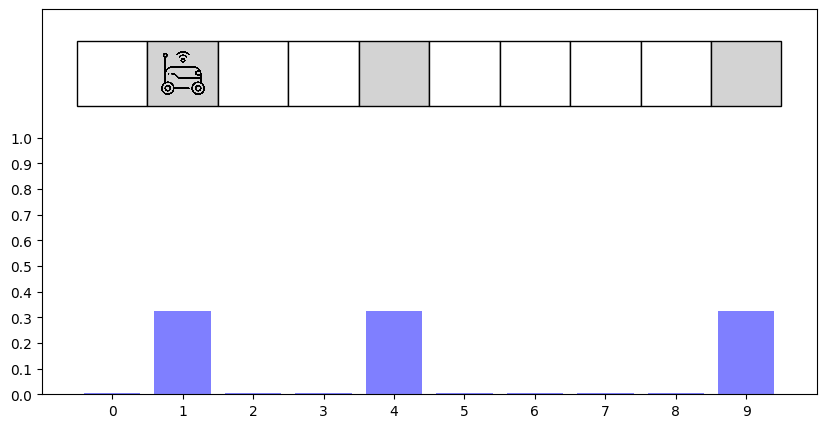

In [59]:

# Draw the robot icon
robot_icon = mpimg.imread('media/robot.png')
imagebox = OffsetImage(robot_icon, zoom=0.075)
ax.add_artist(AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False))

display(fig)

# Update the probabilities based on measurements
for m in measurements:
    for i in range(len(prob)):
        if map_[i] == m:
            prob[i] *= prob_hit
        else:
            prob[i] *= prob_miss

    prob /= np.sum(prob)
    

    input("Press Enter for a new measure...")

    for bar, z in zip(bars, prob):
        bar.set_height(z)
    clear_output(wait=True)
    display(fig)


# Model de Miscare

O modalitate de a deduce pozitia in timp este pe baza de comenzi catre robot. Metoda se numeste "Dead Reckoning" si are ca baza un model matematic ce descrie legatura dintre comanda si evolutia starii. Comanda se noteaza in mod uzual cu $\mathbf{u}_{k}$ si rezultatul obtinut din aceasta metoda se noteaza $p(\mathbf{x}_k \mid \mathbf{u}_{1:k-1})$.

Modele folosite uzual sunt o aproximare a dinaminii procesului real. De aceea, in prezicerea pozitiei viitoare pe se adauga o incertitudine in calcule, denumita "zgomot de proces". Acest zgomot reprezinta variabile lipsite din model (ex vant, forte de frecare, intarzieri ale comenzii, zgomot electric, etc. ).

In [19]:
def shift_prob(arr, dir, motion_hit, motion_miss):
    new_prob = np.zeros_like(arr)
    for i in range(len(arr)):
        new_prob[i] = arr[(i + dir) % len(arr)] * motion_hit + arr[i] * motion_miss + arr[(i + 2*dir) % len(arr)] * motion_miss
    return new_prob

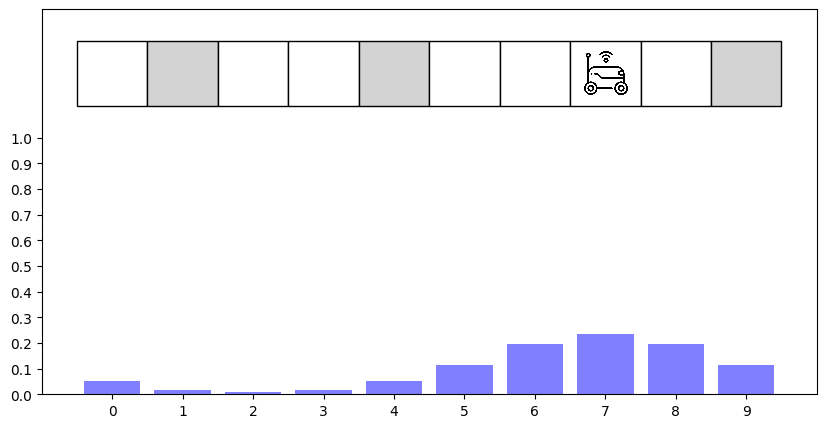

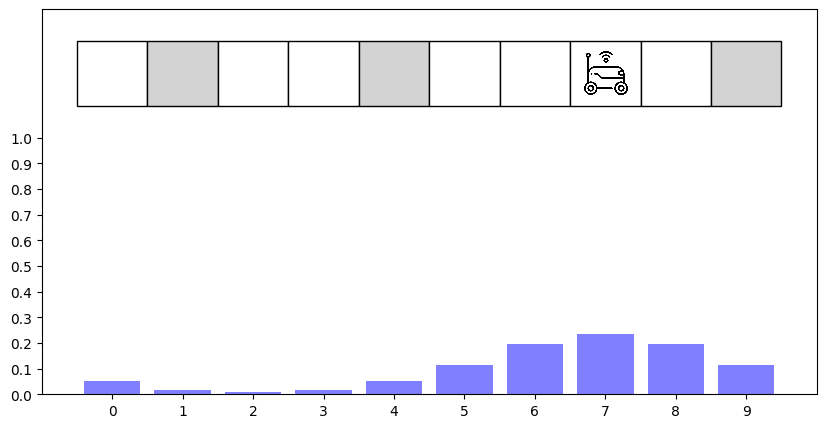

In [20]:
map_ = [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
prob = np.zeros_like(map_, dtype=np.float32)
cell_width = 1
cell_height = 0.25
motion_prob = 0.8
miss_prob = (1.0 - motion_prob)/2
robot_index = 1

fig, ax = plt.subplots(figsize=(10, 5))

# Draw the map
for i in range(len(map_)):
    if map_[i]:
        color = 'lightgray'
    else:
        color = 'white'
    square = mpatches.Rectangle((i * cell_width - cell_width/2, 1.25-cell_height/2), cell_width, cell_height, facecolor=color, edgecolor='black', linewidth=1)
    ax.add_patch(square)

# Draw the probability bars
prob[robot_index] = motion_prob
prob[(robot_index - 1) % len(map_)] = miss_prob
prob[(robot_index + 1) % len(map_)] = miss_prob

bars = ax.bar(range(len(prob)), prob, color='blue', alpha=0.5, label='Probability')
ax.set_ylim(0,1.5)
ax.set_xticks(range(len(map_)))
ax.set_yticks(np.arange(0, 1.1, 0.1))

# Draw the robot icon
robot_icon = mpimg.imread('media/robot.png')
imagebox = OffsetImage(robot_icon, zoom=0.075)
annot = AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False)
ax.add_artist(annot)
display(fig)

while True:
    key = input("Press 'a' or 'd' to move the robot, or 'q' to quit...")

    if key == 'q':
        break
    elif key == 'a':
        dir = 1
    elif key == 'd':
        dir = -1

    prob = shift_prob(prob, dir, motion_prob, miss_prob)
    prob /= np.sum(prob)
    robot_index = (robot_index - dir) % len(map_)

    annot.remove()
    annot = AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False)
    ax.add_artist(annot)

    for bar, z in zip(bars, prob):
            bar.set_height(z)
    clear_output(wait=True)
    display(fig)


# Predict and Update

Avand un model atat pentru senzot cat si pentru miscare, putem aplica algoritmul in mod iterativ. La fiecare esantionare a senzorului, se calculeaza "cum a evoluat distributia cat timp nu au fost facute masurat?", iar noua masuratoare se aplica pentru corectie.

$$p(\mathbf{x}_k \mid \mathbf{z}_{1:k}) = \frac{p(\mathbf{z}_k \mid \mathbf{x}_k) \, p(\mathbf{x}_k \mid \mathbf{z}_{1:k-1}, \mathbf{u}_{1:k})}{p(\mathbf{z}_k)}$$

In mod uzual, numitorul este doar un termen de normalizare si nu este calculat implicit. El reprezinta probabilitate de a avea o anumita masuratoare lunad in calcul toate posibilile stari ale robotului.

In [44]:
from scipy.stats import bernoulli

def measure(prob, map_, robot_index, prob_hit):

    if map_[robot_index] == 1:
        p = prob_hit
    else:
        p = 1 - prob_hit
    
    measurement = bernoulli.rvs(p, size=1)[0]

    for i in range(len(prob)):
        if map_[i] == measurement:
            prob[i] *= prob_hit
        else:
            prob[i] *= prob_miss
    prob /= np.sum(prob)
    return prob

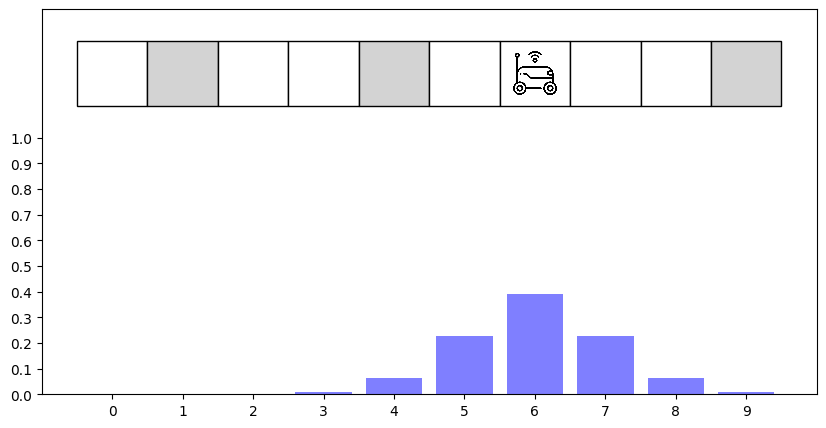

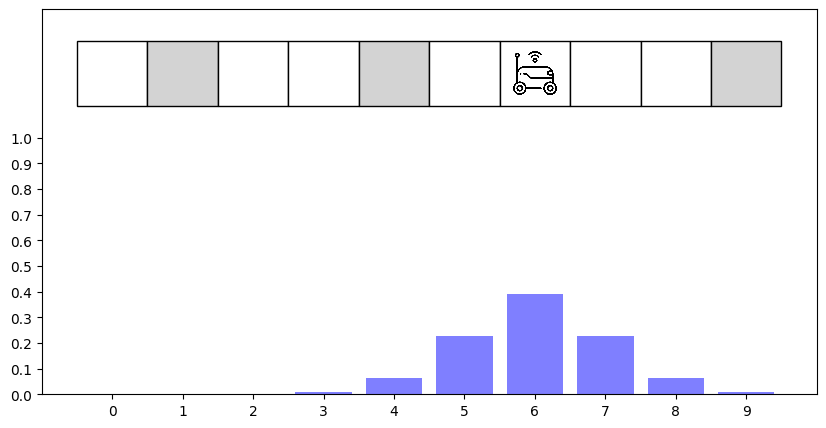

In [48]:
map_ = [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
prob = np.zeros_like(map_, dtype=np.float32)
cell_width = 1
cell_height = 0.25
motion_hit = 0.8
motion_miss = (1.0 - motion_hit) / 2
robot_index = 1

prob_hit = 1.0
prob_miss = 1.0 - prob_hit

fig, ax = plt.subplots(figsize=(10, 5))

# Draw the map
for i in range(len(map_)):
    if map_[i]:
        color = 'lightgray'
    else:
        color = 'white'
    square = mpatches.Rectangle((i * cell_width - cell_width/2, 1.25-cell_height/2), cell_width, cell_height, facecolor=color, edgecolor='black', linewidth=1)
    ax.add_patch(square)

# Draw the probability bars
prob[robot_index] = motion_hit
prob[(robot_index - 1) % len(map_)] = motion_miss
prob[(robot_index + 1) % len(map_)] = motion_miss

bars = ax.bar(range(len(prob)), prob, color='blue', alpha=0.5, label='Probability')
ax.set_ylim(0,1.5)
ax.set_xticks(range(len(map_)))
ax.set_yticks(np.arange(0, 1.1, 0.1))

# Draw the robot icon
robot_icon = mpimg.imread('media/robot.png')
imagebox = OffsetImage(robot_icon, zoom=0.075)
annot = AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False)
ax.add_artist(annot)
display(fig)

while True:
    key = input("Press 'a' or 'd' to move the robot, 's' to measure or 'q' to quit...")

    dir = None

    if key == 'q':
        break
    elif key == 'a':
        dir = 1
    elif key == 'd':
        dir = -1
    elif key == 's':
        dir = 0

    if dir:
        prob = shift_prob(prob, dir, motion_hit, motion_miss)
        robot_index = (robot_index - dir) % len(map_)

        annot.remove()
        annot = AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False)
        ax.add_artist(annot)
    elif dir == 0:
        prob = measure(prob, map_, robot_index, prob_hit)

    for bar, z in zip(bars, prob):
            bar.set_height(z)
    clear_output(wait=True)

    display(fig)

# TODO

Extindeti exemplul 1D la unul 2D. Dezvolati urmatoarele componente:
* Model de senzor                                                  
* Model de miscare                                                  
* Pas de predictie                                                
* Pas de corectie                                                   
* O convergenta sesizabila a increderii in pozitiei                

ValueError: not enough values to unpack (expected 2, got 1)

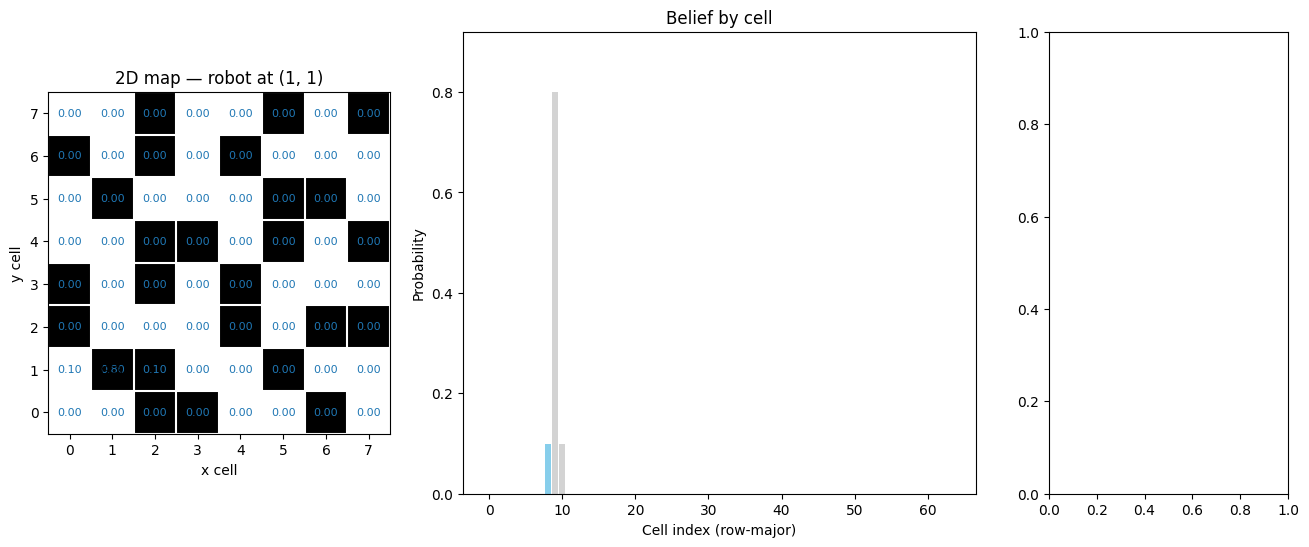

In [61]:
# Uses the existing np, plt, display, clear_output, and robot_icon variables.

map2d = np.array([
    [0, 0, 1, 1, 0, 0, 1, 0],
    [0, 1, 1, 0, 0, 1, 0, 0],
    [1, 0, 0, 0, 1, 0, 1, 1],
    [1, 0, 1, 0, 1, 0, 0, 0],
    [0, 0, 1, 1, 0, 1, 0, 1],
    [0, 1, 0, 0, 0, 1, 1, 0],
    [1, 0, 1, 0, 1, 0, 0, 0],
    [0, 0, 1, 0, 0, 1, 0, 1],
])

height2d, width2d = map2d.shape
robot_xy2d = (1, 1)  # (x, y)

motion_hit_2d = 0.8
motion_miss_2d = (1.0 - motion_hit_2d) / 2
prob_hit = 0.75
prob_miss = 1.0 - prob_hit

cmds = {
    "w": (0, 1),
    "s": (0, -1),
    "a": (-1, 0),
    "d": (1, 0),
}


def motion_kernel2d(action):
    """Return a 3x3 motion-probability matrix; the top row is positive y."""
    dx, dy = action
    if dx:
        outcomes = [(dx, dy, motion_hit_2d),
                    (0, 1, motion_miss_2d),
                    (0, -1, motion_miss_2d)]
    else:
        outcomes = [(dx, dy, motion_hit_2d),
                    (1, 0, motion_miss_2d),
                    (-1, 0, motion_miss_2d)]

    kernel = np.zeros((3, 3))
    for ox, oy, probability in outcomes:
        kernel[1 - oy, 1 + ox] += probability
    return kernel


# Start with the same 0.8 / 0.1 / 0.1 weights, centered on the known start.
belief2d = np.zeros((height2d, width2d))
x0, y0 = robot_xy2d
for dx, dy, probability in [
    (0, 0, motion_hit_2d),
    (-1, 0, motion_miss_2d),
    (1, 0, motion_miss_2d),
]:
    x = int(np.clip(x0 + dx, 0, width2d - 1))
    y = int(np.clip(y0 + dy, 0, height2d - 1))
    belief2d[y, x] += probability
belief2d /= belief2d.sum()


def predict2d(belief, action):
    dx, dy = action
    if dx:
        outcomes = [(dx, dy, motion_hit_2d),
                    (0, 1, motion_miss_2d),
                    (0, -1, motion_miss_2d)]
    else:
        outcomes = [(dx, dy, motion_hit_2d),
                    (1, 0, motion_miss_2d),
                    (-1, 0, motion_miss_2d)]

    predicted = np.zeros_like(belief)
    for y in range(height2d):
        for x in range(width2d):
            for ox, oy, probability in outcomes:
                nx = int(np.clip(x + ox, 0, width2d - 1))
                ny = int(np.clip(y + oy, 0, height2d - 1))
                predicted[ny, nx] += belief[y, x] * probability
    return predicted / predicted.sum()


def move_robot2d(position, action):
    x, y = position
    dx, dy = action
    outcomes = ([(dx, dy), (0, 1), (0, -1)] if dx
                else [(dx, dy), (1, 0), (-1, 0)])
    ox, oy = outcomes[
        np.random.choice(3, p=[motion_hit_2d, motion_miss_2d, motion_miss_2d])
    ]
    return (int(np.clip(x + ox, 0, width2d - 1)),
            int(np.clip(y + oy, 0, height2d - 1)))


def measure2d(belief, measurement):
    likelihood = np.where(map2d == measurement, prob_hit, prob_miss)
    updated = belief * likelihood
    return updated / updated.sum()


def draw2d(action="w"):
    ax_map.clear()
    ax_bars.clear()
    ax_kernel.clear()

    # Map cells and belief labels
    ax_map.imshow(map2d, origin="lower", cmap="Greys", vmin=0, vmax=1)
    ax_map.set_xticks(np.arange(width2d))
    ax_map.set_yticks(np.arange(height2d))
    ax_map.set_xticks(np.arange(-0.5, width2d, 1), minor=True)
    ax_map.set_yticks(np.arange(-0.5, height2d, 1), minor=True)
    ax_map.grid(which="minor", color="white", linewidth=1.5)
    ax_map.tick_params(which="minor", bottom=False, left=False)

    for y in range(height2d):
        for x in range(width2d):
            ax_map.text(x, y, f"{belief2d[y, x]:.2f}",
                        ha="center", va="center", color="tab:blue", fontsize=8)

    rx, ry = robot_xy2d
    ax_map.imshow(
        robot_icon,
        extent=(rx - 0.35, rx + 0.35, ry - 0.35, ry + 0.35),
        zorder=3,
    )
    ax_map.set(
        title=f"2D map — robot at {robot_xy2d}",
        xlabel="x cell",
        ylabel="y cell",
        xlim=(-0.5, width2d - 0.5),
        ylim=(-0.5, height2d - 0.5),
    )

    # Belief bar chart, one bar per map cell
    colors = np.where(map2d.ravel() == 1, "lightgray", "skyblue")
    ax_bars.bar(np.arange(map2d.size), belief2d.ravel(), color=colors)
    ax_bars.set(
        title="Belief by cell",
        xlabel="Cell index (row-major)",
        ylabel="Probability",
        ylim=(0, max(0.05, float(belief2d.max()) * 1.15)),
    )

    # Motion probabilities for the displayed action
    kernel = motion_kernel2d(action)
    ax_kernel.imshow(kernel, cmap="Blues", vmin=0, vmax=motion_hit_2d)
    for row in range(3):
        for col in range(3):
            ax_kernel.text(col, row, f"{kernel[row, col]:.2f}",
                           ha="center", va="center")
    ax_kernel.set(
        title=f"Motion matrix ({action})",
        xticks=[0, 1, 2],
        yticks=[0, 1, 2],
        xlabel="Δx",
        ylabel="Δy (positive upward)",
    )

    fig.tight_layout()


fig, (ax_map, ax_bars, ax_kernel) = plt.subplots(
    1, 3, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.5, 0.7]}
)
draw2d()
display(fig)

while True:
    command = input("Move with w/a/s/d, measure with m, or quit with q: ").lower()

    if command == "q":
        break
    elif command in cmds:
        action = cmds[command]
        belief2d = predict2d(belief2d, action)
        robot_xy2d = move_robot2d(robot_xy2d, action)
    elif command == "m":
        x, y = robot_xy2d
        true_value = map2d[y, x]
        measurement = int(np.random.random() < (
            prob_hit if true_value == 1 else prob_miss
        ))
        belief2d = measure2d(belief2d, measurement)
        print(f"Sensor reading: {measurement}")
    else:
        print("Unknown command.")
        continue

    clear_output(wait=True)
    draw2d(command if command in cmds else "w")
    display(fig)